In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/run_pcaAll.sh

Streaming output truncated to the last 5000 lines.
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 255/1456 (remaining item 255/1456)
Index into batch for prf 254: 54
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 256/1456 (remaining item 256/1456)
Index into batch for prf 255: 55
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 257/1456 (remaining item 257/1456)
Index into batch for prf 256: 56
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 258/1456 (remaining item 258/1456)
Index into batch for prf 257: 57
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 259/1456 (remaining item 259/1456)
Index into batch for prf 258: 58
Final size of feature matrix for this image set and pRF is:
(10000, 641)
Writing scores: pRF 260/1456 (remaining item 260/1456)
Index into batch

In [ ]:
# # The existing concat files are from the older PCA run.
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v40/S8_4ori_4sf_pcaAll_concat_v40pct_grid5.h5py
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v60/S8_4ori_4sf_pcaAll_concat_v60pct_grid5.h5py
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v80/S8_4ori_4sf_pcaAll_concat_v80pct_grid5.h5py
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v95/S8_4ori_4sf_pcaAll_concat_v95pct_grid5.h5py

!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v40/S8_4ori_4sf_featurelabels_pcaAll_v40pct_grid5.npy
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v60/S8_4ori_4sf_featurelabels_pcaAll_v60pct_grid5.npy
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v80/S8_4ori_4sf_featurelabels_pcaAll_v80pct_grid5.npy
!rm -f /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaAll_v95/S8_4ori_4sf_featurelabels_pcaAll_v95pct_grid5.npy



In [ ]:
import os
import h5py
import numpy as np

base = "/content/drive/MyDrive/V2_drift/features/pyramid_texture"

files = {
    40: {
        "h5": f"{base}/PCA_pcaAll_v40/S1_4ori_4sf_pcaAll_concat_v40pct_grid5.h5py",
        "labels": f"{base}/PCA_pcaAll_v40/S1_4ori_4sf_featurelabels_pcaAll_v40pct_grid5.npy",
    },
    60: {
        "h5": f"{base}/PCA_pcaAll_v60/S1_4ori_4sf_pcaAll_concat_v60pct_grid5.h5py",
        "labels": f"{base}/PCA_pcaAll_v60/S1_4ori_4sf_featurelabels_pcaAll_v60pct_grid5.npy",
    },
    80: {
        "h5": f"{base}/PCA_pcaAll_v80/S1_4ori_4sf_pcaAll_concat_v80pct_grid5.h5py",
        "labels": f"{base}/PCA_pcaAll_v80/S1_4ori_4sf_featurelabels_pcaAll_v80pct_grid5.npy",
    },
    95: {
        "h5": f"{base}/PCA_pcaAll_v95/S1_4ori_4sf_pcaAll_concat_v95pct_grid5.h5py",
        "labels": f"{base}/PCA_pcaAll_v95/S1_4ori_4sf_featurelabels_pcaAll_v95pct_grid5.npy",
    },
}

for threshold, paths in files.items():

    print(f"\n===== pcaAll {threshold}% =====")

    assert os.path.exists(paths["h5"])
    assert os.path.exists(paths["labels"])

    with h5py.File(paths["h5"], "r") as f:
        x = f["features"]
        completed = f["completed_image_chunks"][:]

        print("shape:", x.shape)
        print("dtype:", x.dtype)
        print("completed chunks:", completed)

        assert x.shape[0] == 10000
        assert x.shape[2] == 1456
        assert np.all(completed == 1)

        n_components_each_prf = []
        mixed_nan_columns = []

        for prf in range(x.shape[2]):
            prf_data = x[:, :, prf]

            # A feature column must be either fully finite or fully NaN.
            column_all_finite = np.all(np.isfinite(prf_data), axis=0)
            column_all_nan = np.all(np.isnan(prf_data), axis=0)

            invalid_columns = ~(column_all_finite | column_all_nan)

            if np.any(invalid_columns):
                mixed_nan_columns.append(prf)

            n_defined = int(np.sum(column_all_finite))
            n_components_each_prf.append(n_defined)

            # Defined PCs should come first, followed only by NaN padding.
            expected_defined = np.arange(x.shape[1]) < n_defined

            assert np.array_equal(
                column_all_finite,
                expected_defined,
            ), f"Non-contiguous PC columns at pRF {prf}"

        n_components_each_prf = np.asarray(n_components_each_prf)

        print(
            "PC count distribution:",
            np.unique(n_components_each_prf, return_counts=True),
        )
        print("Mixed finite/NaN columns:", len(mixed_nan_columns))

        assert len(mixed_nan_columns) == 0
        assert np.all(n_components_each_prf >= 1)

    labels_obj = np.load(paths["labels"], allow_pickle=True).item()
    labels = labels_obj["feature_column_labels"]
    names = labels_obj["feature_type_names"]

    print("labels shape:", labels.shape)
    print("feature names:", names)

    assert len(labels) == x.shape[1]

    print("CHECK PASSED")


===== pcaAll 40% =====
shape: (10000, 2, 1456)
dtype: float32
completed chunks: [1 1 1 1 1 1 1 1 1 1]
PC count distribution: (array([1, 2]), array([1454,    2]))
Mixed finite/NaN columns: 0
labels shape: (2,)
feature names: ['all_features']
CHECK PASSED

===== pcaAll 60% =====
shape: (10000, 2, 1456)
dtype: float32
completed chunks: [1 1 1 1 1 1 1 1 1 1]
PC count distribution: (array([1, 2]), array([1412,   44]))
Mixed finite/NaN columns: 0
labels shape: (2,)
feature names: ['all_features']
CHECK PASSED

===== pcaAll 80% =====
shape: (10000, 3, 1456)
dtype: float32
completed chunks: [1 1 1 1 1 1 1 1 1 1]
PC count distribution: (array([1, 2, 3]), array([1178,  261,   17]))
Mixed finite/NaN columns: 0
labels shape: (3,)
feature names: ['all_features']
CHECK PASSED

===== pcaAll 95% =====
shape: (10000, 5, 1456)
dtype: float32
completed chunks: [1 1 1 1 1 1 1 1 1 1]
PC count distribution: (array([1, 2, 3, 4, 5]), array([807, 278, 290,  66,  15]))
Mixed finite/NaN columns: 0
labels shape:

In [ ]:
import os

folder = "/content/drive/MyDrive/V2_drift/features/pyramid_texture"

print(sorted(os.listdir(folder)))

['PCA_pcaAll_MULTI', 'PCA_pcaAll_v0', 'PCA_pcaAll_v10', 'PCA_pcaAll_v20', 'PCA_pcaAll_v30', 'PCA_pcaAll_v40', 'PCA_pcaAll_v60', 'PCA_pcaAll_v80', 'PCA_pcaAll_v90', 'PCA_pcaAll_v95', 'PCA_pcaHL_MULTI', 'PCA_pcaHL_v0', 'PCA_pcaHL_v10', 'PCA_pcaHL_v20', 'PCA_pcaHL_v30', 'PCA_pcaHL_v40', 'PCA_pcaHL_v60', 'PCA_pcaHL_v80', 'PCA_pcaHL_v90', 'PCA_pcaHL_v95', 'plots']


In [ ]:
import glob
import h5py
import numpy as np
import os

folder = "/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_allPCs"

files = sorted(glob.glob(os.path.join(folder, "S8*.h5py")))

for fn in files:
    print("="*80)
    print(os.path.basename(fn))

    with h5py.File(fn, "r") as f:
        print("Keys:", list(f.keys()))

        for k in f.keys():
            arr = f[k]

            print(
                k,
                arr.shape,
                arr.dtype,
            )

            x = arr[:]

            print(
                " NaN:", np.isnan(x).sum(),
                " Inf:", np.isinf(x).sum(),
                " Min:", np.min(x),
                " Max:", np.max(x),
            )

S8_4ori_4sf_pcaHL_concat_allPCs_grid5.h5py
Keys: ['features']
features (10000, 519, 1456) float32


KeyboardInterrupt: 

# check all subjects for both pcaHL and pcaAll, collect:

number of final PCA features
mean valid features per pRF
min/max valid features per pRF
maybe whether NaNs exist

and then make comparison plots.

,subject,pca_pct,pca_type,n_low_features,n_high_features,n_total
0,8,0,pcaAll,5,9,14
1,8,0,pcaHL,49,9,58
2,8,10,pcaAll,5,9,14
3,8,10,pcaHL,49,9,58
4,8,20,pcaAll,5,10,15
5,8,20,pcaHL,49,10,59
6,8,30,pcaAll,5,12,17
7,8,30,pcaHL,49,12,61
8,8,40,pcaAll,5,15,20
9,8,40,pcaHL,49,15,64


Saved figure to: /content/drive/MyDrive/V2_drift/features/pyramid_texture/plots/S8_feature_count_PCA_thresholds_grid5.png


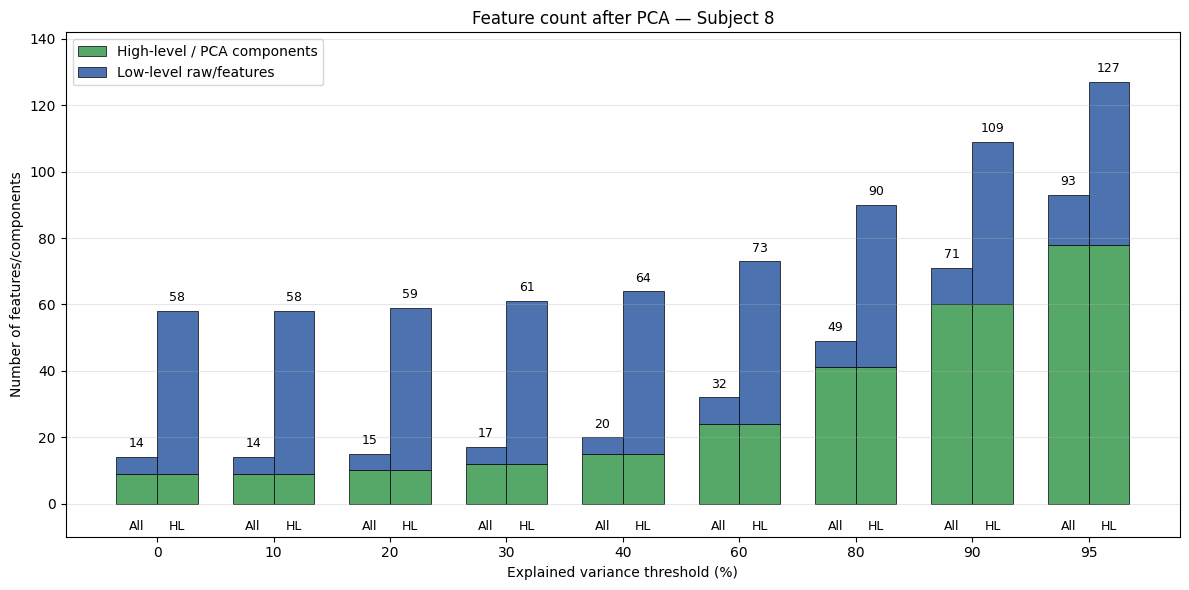

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# SETTINGS
# =========================================================

ROOT = "/content/drive/MyDrive/V2_drift/features/pyramid_texture"

SUBJECT = 8
GRID = 5

PCA_PCTS = [0, 10, 20, 30, 40, 60, 80, 90, 95]

LOW_LEVEL_LABELS = [0, 1, 2, 3, 4]

SAVE_DIR = os.path.join(ROOT, "plots")
os.makedirs(SAVE_DIR, exist_ok=True)

# =========================================================
# LOAD FEATURE LABEL COUNTS
# =========================================================

rows = []

for pca_pct in PCA_PCTS:

    var_str = f"v{pca_pct}pct"

    configs = [
        ("pcaAll", f"PCA_pcaAll_v{pca_pct}"),
        ("pcaHL",  f"PCA_pcaHL_v{pca_pct}"),
    ]

    for pca_type, folder in configs:

        label_file = os.path.join(
            ROOT,
            folder,
            f"S{SUBJECT}_4ori_4sf_featurelabels_{pca_type}_{var_str}_grid{GRID}.npy"
        )

        if not os.path.exists(label_file):
            print("Missing:", label_file)
            continue

        labels = np.load(label_file, allow_pickle=True).item()
        feature_labels = labels["feature_column_labels"]

        is_low = np.isin(feature_labels, LOW_LEVEL_LABELS)
        is_high = ~is_low

        rows.append({
            "subject": SUBJECT,
            "pca_pct": pca_pct,
            "pca_type": pca_type,
            "n_low_features": int(np.sum(is_low)),
            "n_high_features": int(np.sum(is_high)),
            "n_total": len(feature_labels),
        })

df = pd.DataFrame(rows)

display(df)

# =========================================================
# CHECK THAT BOTH PCA TYPES EXIST FOR EACH THRESHOLD
# =========================================================

expected_n = len(PCA_PCTS) * 2

if len(df) != expected_n:
    print(f"Warning: expected {expected_n} rows, found {len(df)}.")
    print("Some PCA threshold/type files may be missing.")

# =========================================================
# PREPARE PLOT DATA
# =========================================================

all_df = (
    df[df["pca_type"] == "pcaAll"]
    .sort_values("pca_pct")
    .reset_index(drop=True)
)

hl_df = (
    df[df["pca_type"] == "pcaHL"]
    .sort_values("pca_pct")
    .reset_index(drop=True)
)

# keep only thresholds available in both
common_pcts = sorted(
    set(all_df["pca_pct"]).intersection(set(hl_df["pca_pct"]))
)

all_df = all_df[all_df["pca_pct"].isin(common_pcts)].sort_values("pca_pct").reset_index(drop=True)
hl_df = hl_df[hl_df["pca_pct"].isin(common_pcts)].sort_values("pca_pct").reset_index(drop=True)

x = np.arange(len(common_pcts))
width = 0.35

# =========================================================
# PLOT
# =========================================================

fig, ax = plt.subplots(figsize=(12, 6))

low_color = "#4C72B0"
high_color = "#55A868"
edge_color = "black"
linewidth = 0.5

# -------------------------
# pcaAll
# -------------------------
bars_all_high = ax.bar(
    x - width / 2,
    all_df["n_high_features"],
    width,
    color=high_color,
    edgecolor=edge_color,
    linewidth=linewidth,
    label="High-level / PCA components",
)

bars_all_low = ax.bar(
    x - width / 2,
    all_df["n_low_features"],
    width,
    bottom=all_df["n_high_features"],
    color=low_color,
    edgecolor=edge_color,
    linewidth=linewidth,
    label="Low-level raw/features",
)

# -------------------------
# pcaHL
# -------------------------
bars_hl_high = ax.bar(
    x + width / 2,
    hl_df["n_high_features"],
    width,
    color=high_color,
    edgecolor=edge_color,
    linewidth=linewidth,
)

bars_hl_low = ax.bar(
    x + width / 2,
    hl_df["n_low_features"],
    width,
    bottom=hl_df["n_high_features"],
    color=low_color,
    edgecolor=edge_color,
    linewidth=linewidth,
)

# =========================================================
# ANNOTATIONS
# =========================================================

for i in range(len(common_pcts)):

    total_all = int(all_df.loc[i, "n_total"])
    total_hl = int(hl_df.loc[i, "n_total"])

    ax.text(
        x[i] - width / 2,
        total_all + 2,
        str(total_all),
        ha="center",
        va="bottom",
        fontsize=9,
    )

    ax.text(
        x[i] + width / 2,
        total_hl + 2,
        str(total_hl),
        ha="center",
        va="bottom",
        fontsize=9,
    )

    ax.text(
        x[i] - width / 2,
        -5,
        "All",
        ha="center",
        va="top",
        fontsize=9,
    )

    ax.text(
        x[i] + width / 2,
        -5,
        "HL",
        ha="center",
        va="top",
        fontsize=9,
    )

# =========================================================
# AXIS STYLE
# =========================================================

ax.set_xticks(x)
ax.set_xticklabels(common_pcts)

ax.set_xlabel("Explained variance threshold (%)")
ax.set_ylabel("Number of features/components")

ax.set_title(f"Feature count after PCA — Subject {SUBJECT}")

ax.legend(loc="upper left")

max_total = int(df["n_total"].max())
ax.set_ylim(-10, max_total + 15)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# =========================================================
# SAVE
# =========================================================

fname = f"S{SUBJECT}_feature_count_PCA_thresholds_grid{GRID}.png"
save_path = os.path.join(SAVE_DIR, fname)

fig.savefig(save_path, dpi=300, bbox_inches="tight")

print("Saved figure to:", save_path)

plt.show()

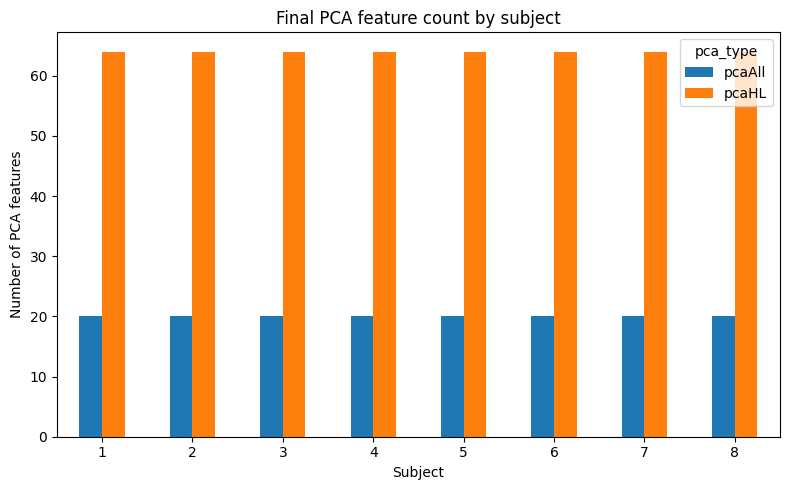

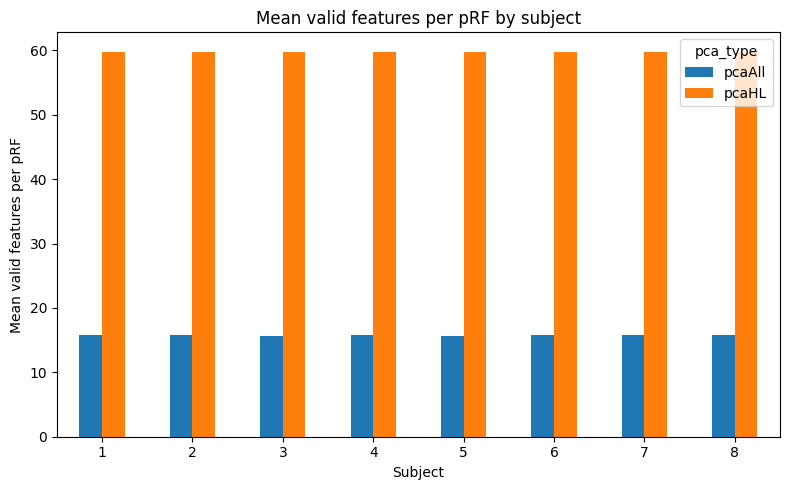

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []

LOW_LEVEL_LABELS = [0, 1, 2, 3, 4]

for subj in SUBJECTS:
    for pca_type, folder in configs:

        label_file = os.path.join(
            ROOT, folder,
            f"S{subj}_4ori_4sf_featurelabels_{pca_type}_{VAR_STR}_grid{GRID}.npy"
        )

        if not os.path.exists(label_file):
            continue

        labels = np.load(label_file, allow_pickle=True).item()
        feature_labels = labels["feature_column_labels"]

        is_low = np.isin(feature_labels, LOW_LEVEL_LABELS)
        is_high = ~is_low

        rows.append({
            "subject": subj,
            "pca_type": pca_type,
            "n_features_total": len(feature_labels),
            "n_low_features": int(np.sum(is_low)),
            "n_high_features": int(np.sum(is_high)),
        })

df = pd.DataFrame(rows)

plot_df = df[[
    "subject",
    "pca_type",
    "n_features_total",
    "n_low_features",
    "n_high_features"
]].copy()

subjects = sorted(plot_df["subject"].unique())
x = np.arange(len(subjects))
width = 0.35

pca_all = plot_df[plot_df["pca_type"] == "pcaAll"].sort_values("subject")
pca_hl = plot_df[plot_df["pca_type"] == "pcaHL"].sort_values("subject")

fig, ax = plt.subplots(figsize=(10, 5))

low_color = "#4C72B0"
high_color = "#55A868"
edge_color = "black"
linewidth = 0.5

# pcaAll: all features are PCA-compressed, so labels are dominant components.
bars_all_high = ax.bar(
    x - width/2,
    pca_all["n_high_features"],
    width,
    color=high_color,
    edgecolor=edge_color,
    linewidth=linewidth,
    label="High-dominant components"
)

bars_all_low = ax.bar(
    x - width/2,
    pca_all["n_low_features"],
    width,
    bottom=pca_all["n_high_features"],
    color=low_color,
    edgecolor=edge_color,
    linewidth=linewidth,
    label="Low-dominant components"
)

# pcaHL: low-level features are raw; high-level features are PCA-compressed.
bars_hl_high = ax.bar(
    x + width/2,
    pca_hl["n_high_features"],
    width,
    color=high_color,
    edgecolor=edge_color,
    linewidth=linewidth
)

bars_hl_low = ax.bar(
    x + width/2,
    pca_hl["n_low_features"],
    width,
    bottom=pca_hl["n_high_features"],
    color=low_color,
    edgecolor=edge_color,
    linewidth=linewidth
)

var_pct = VAR_STR.replace("v", "").replace("pct", "")
ax.set_title(f"Feature count after PCA (≥{var_pct}% variance explained)")
ax.set_xlabel("Subject")
ax.set_ylabel("Number of features/components")

ax.set_xticks(x)
ax.set_xticklabels(subjects)

for i in range(len(subjects)):
    ax.text(x[i] - width/2, -3, "All", ha="center", va="top", fontsize=9)
    ax.text(x[i] + width/2, -3, "HL", ha="center", va="top", fontsize=9)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2])

max_total = plot_df["n_features_total"].max()
ax.set_ylim(0, max_total + 8)

for bars in [bars_all_high, bars_all_low, bars_hl_high, bars_hl_low]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_y() + height/2,
                f"{int(height)}",
                ha="center",
                va="center",
                fontsize=8,
                color="white"
            )

plt.tight_layout()
# ---- SAVE FIGURE ----
save_dir = os.path.join(ROOT, "plots")
os.makedirs(save_dir, exist_ok=True)

fname = f"feature_count_PCA_{VAR_STR}.png"
save_path = os.path.join(save_dir, fname)

fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {save_path}")
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/V2_drift/features/pyramid_texture"
SUBJECTS = range(1, 9)
GRID = 5
vars_to_plot = [40, 60]

configs_template = [
    ("pcaHL", "PCA_pcaHL_v{var}"),
    ("pcaAll", "PCA_pcaAll_v{var}"),
]

rows = []

for var in vars_to_plot:
    VAR_STR = f"v{var}pct"

    for subj in SUBJECTS:
        for pca_type, folder_template in configs_template:
            folder = folder_template.format(var=var)

            label_file = os.path.join(
                ROOT, folder,
                f"S{subj}_4ori_4sf_featurelabels_{pca_type}_{VAR_STR}_grid{GRID}.npy"
            )

            if not os.path.exists(label_file):
                print("Missing:", label_file)
                continue

            labels = np.load(label_file, allow_pickle=True).item()
            n_features = len(labels["feature_column_labels"])

            rows.append({
                "subject": subj,
                "pca_type": pca_type,
                "var_explained": var,
                "n_features": n_features
            })

df_dim = pd.DataFrame(rows)

summary = (
    df_dim
    .groupby(["pca_type", "var_explained"])
    .agg(
        mean_features=("n_features", "mean"),
        std_features=("n_features", "std")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 5))

colors = {
    "pcaAll": "#4C72B0",
    "pcaHL": "#55A868"
}

for pca_type in ["pcaAll", "pcaHL"]:
    sub = summary[summary["pca_type"] == pca_type].sort_values("var_explained")

    ax.errorbar(
        sub["var_explained"],
        sub["mean_features"],
        yerr=sub["std_features"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=colors[pca_type],
        label=pca_type
    )

ax.set_title("PCA dimensionality as a function of explained variance")
ax.set_xlabel("Explained variance threshold (%)")
ax.set_ylabel("Number of retained features/components")
ax.set_xticks(vars_to_plot)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="PCA configuration")

plt.tight_layout()

save_dir = os.path.join(ROOT, "plots")
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "pca_dimensionality_vs_variance.png")
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print("Saved:", save_path)

plt.show()